In [55]:
import pandas as pd
import numpy as np
print(np.__version__)
import csv
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.dates as mdates
import matplotlib.ticker as ticker 
import statistics
from matplotlib.ticker import MultipleLocator
from matplotlib.ticker import MaxNLocator


1.24.3


In [56]:
fig_out = 'figures/'
df_main = pd.read_csv("merged_1927_56_1106.csv")## merged_output_1945_56

df_main['date'] = pd.to_datetime(
    df_main[['YYYY', 'MM', 'DD']].rename(
        columns={'YYYY': 'year', 'MM': 'month', 'DD': 'day'}
    )
)
df_main = df_main.sort_values('date')
df_main = df_main.replace(9999, np.nan)

df_main = df_main.replace(9999.0, np.nan)
df_main = df_main.replace(99999, np.nan)
df_main = df_main.replace('99999', np.nan)
df_main = df_main.replace('9999', np.nan)
print(df_main["1"].count()*27)

147744


In [57]:
carnegie_main = [118, 113.7, 111.4, 111.4, 113.5, 117.3, 121.2, 123.2,

            123.0, 122.2, 123.3, 127.7, 134.5, 141.2, 146.0, 148.6,

            150.7, 153.3, 155.8, 156.1, 152.2, 144.3, 134.4, 125.1]

carnegie = [123.64, 118.1, 115.12, 114.49, 116.43, 120.59, 

            125.39, 128.66, 129.34, 128.63, 129.28, 133.41, 

            140.81, 149.19, 156.12, 160.89, 164.53, 168.08, 

            170.94, 170.87, 165.86, 156.01, 143.76, 132.28]

In [58]:
for d in df_main['Day_type'].unique():
    subset = df_main[df_main['Day_type'] == d]
    #print(d, len(subset))

In [59]:
df_main['Day_type'] = pd.to_numeric(df_main['Day_type'], errors='coerce')

df_0 = df_main[df_main['Day_type'] == 0].copy()
df_1 = df_main[df_main['Day_type'] == 1].copy()#) and (df_main['Day_type'] ==2)]
df_2 = df_main[df_main['Day_type'] == 2].copy()
df_mix = df_main[df_main['Day_type'].isin([9, 9999])]
select_df = {
    0: df_0,
    1: df_1,
    2: df_2,
    9: df_mix,
    5:df_main
}
df_before = df_main[df_main['YYYY'] <= 1945]
df_after  = df_main[df_main['YYYY'] > 1945]
#print (df_before['16'])
df_main['Multiplier'] = pd.to_numeric(df_main['Multiplier'], errors='coerce')
#df_main['Multiplier']=df_main['Multiplier'].replace(9999, np.nan)

In [60]:
hour_cols = [str(i) for i in range(1, 25)]
valid = df_main[hour_cols].replace(9999, pd.NA)
valid = valid.apply(pd.to_numeric, errors='coerce')
valid0 = df_0[hour_cols].replace(9999, pd.NA)
valid0 = valid0.apply(pd.to_numeric, errors='coerce')

variable_df = df_main
# make date
dates = pd.to_datetime(
    variable_df[['YYYY','MM']].rename(columns={'YYYY':'year','MM':'month'}).assign(day=1)
)

valid300 = valid.where((valid <= 300) & (valid >= 0))
valid200 = valid.where((valid <= 200) & (valid >= 0))
validmix = valid.where(valid <= 0)

hourly_avg = valid.mean(axis=0)   # column-wise mean
hourly_avg300 = valid300.mean(axis=0)
hourly_avg200 = valid200.mean(axis=0)
hourly_avgmix = validmix.mean(axis=0)

counts = valid.groupby([df_main['YYYY'], df_main['MM']]).count().sum(axis=1).reset_index(name='measurements')
#print(counts)
counts['date'] = pd.to_datetime(counts[['YYYY','MM']].rename(
    columns={'YYYY': 'year', 'MM': 'month'}).assign(day=1))

In [61]:
# average per day (across 24 hours)
df_main['daily_mean'] = valid.mean(axis=1)


df_0['daily_mean'] = valid0.mean(axis=1)


# monthly mean across all years
monthly_mean = df_main.groupby('MM')['daily_mean'].mean()
yearly_mean = df_main.groupby('YYYY')['daily_mean'].mean()

name_='Day Type'
variable = yearly_mean

#print(monthly_mean)

In [62]:
monthly_stats = df_main.groupby('MM')['daily_mean'].agg(
    mean='mean',
    min='min',
    max='max'
)

yearly_stats = df_main.groupby('YYYY')['daily_mean'].agg(
    mean='mean',
    min='min',
    max='max'
)
monthly_stats['range'] = monthly_stats['max'] - monthly_stats['min']

#print(monthly_stats)
monthly_stats['lower'] = monthly_stats['mean'] - monthly_stats['min']
monthly_stats['upper'] = monthly_stats['max'] - monthly_stats['mean']

In [63]:
monthly_counts = (
    valid.groupby([df_main['YYYY'], df_main['MM']])
    .count()
    .sum(axis=1)
)
monthly_counts = monthly_counts.reset_index(name='count')

monthly_counts['date'] = pd.to_datetime(
    monthly_counts[['YYYY', 'MM']]
    .rename(columns={'YYYY': 'year', 'MM': 'month'})
    .assign(day=1)
)

monthly_counts.to_csv('monthly_counts.csv', index=False)


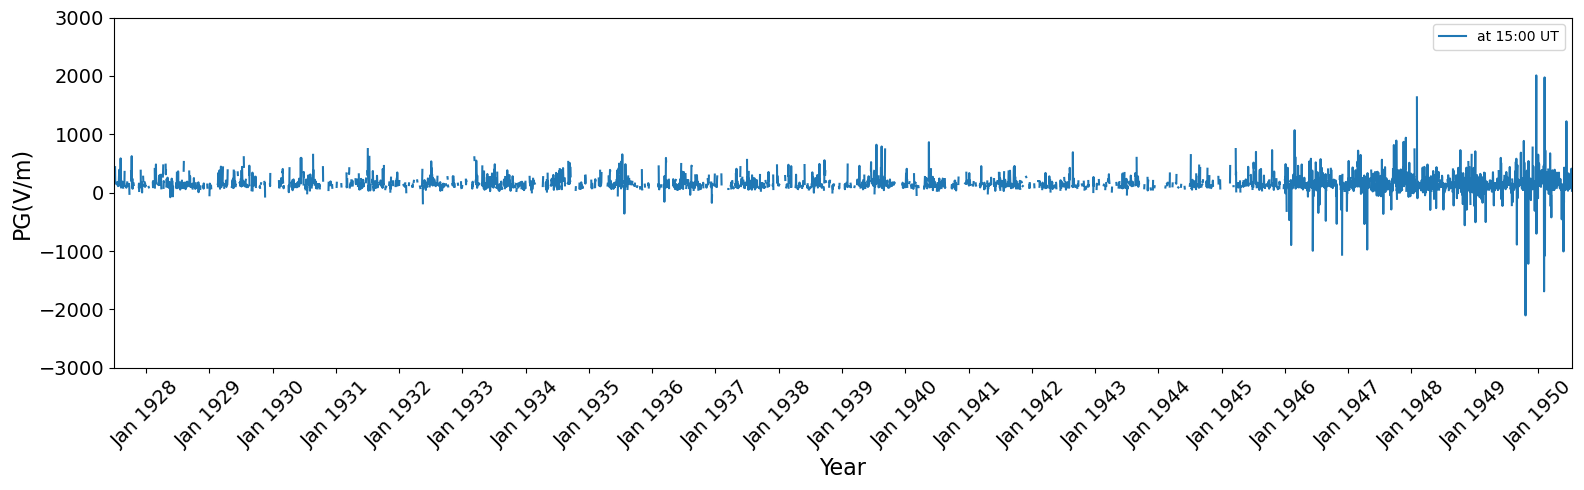

In [64]:
i=15
plt.figure(figsize=(16, 5))

plt.plot(df_main['date'], df_main[str(i)], label=f'at {i}:00 UT')
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator(1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.set_xlim(pd.Timestamp('1927-07-01'),
            pd.Timestamp('1950-07-15'))
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)
plt.xlabel('Year', fontsize=16)
plt.ylabel('PG(V/m)', fontsize=16)
#plt.title('Selected hour from 1927-1956')
plt.legend()
plt.xticks(rotation=45)
plt.ylim(-3000, 3000)
plt.tight_layout()
plt.savefig(f'curve_1927_56_{i}_1.png', dpi=300)
plt.show()

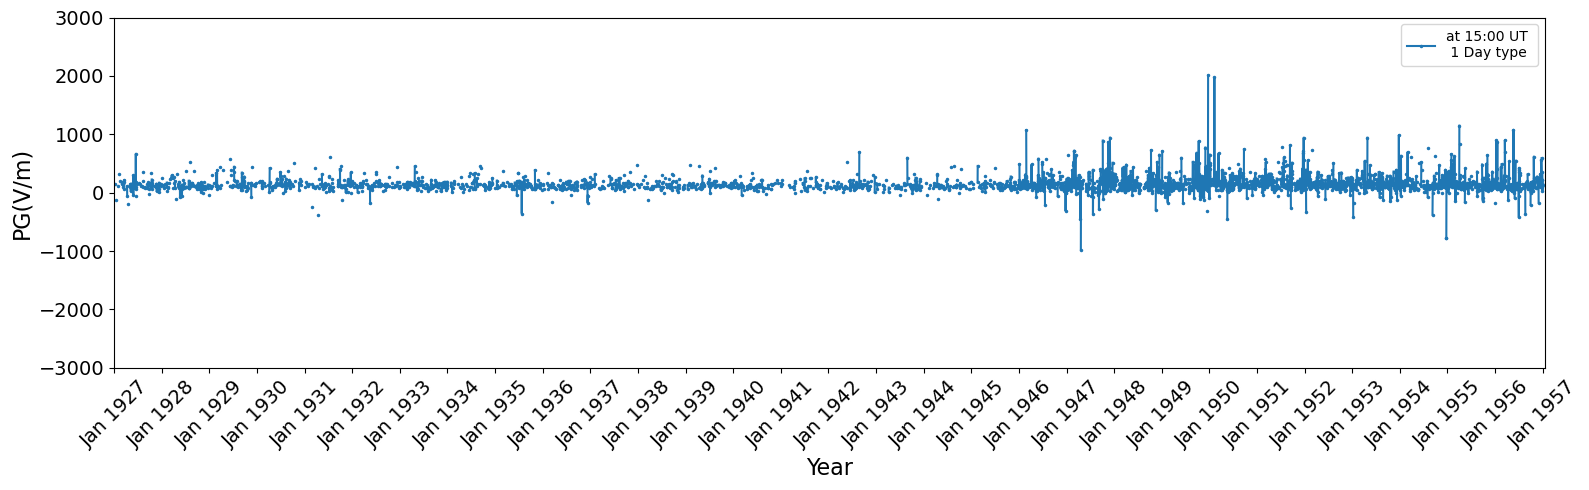

In [65]:
i=15
dt=1
daytype_df =select_df[dt].sort_values('date')

tmp = daytype_df[['date', str(i)]].copy()

gap = tmp['date'].diff().dt.days
break_idx = tmp.index[gap > 1]

rows = []
for idx, row in tmp.iterrows():
    if idx in break_idx:
        rows.append([pd.NaT, np.nan])  # break line
    rows.append([row['date'], row[str(i)]])

plot_df = pd.DataFrame(rows, columns=['date', str(i)])
plot_df['date'] = pd.to_datetime(plot_df['date'], errors='coerce')
plot_df[str(i)] = pd.to_numeric(plot_df[str(i)], errors='coerce')


plt.figure(figsize=(16, 5))

plt.plot(plot_df['date'],
         plot_df[str(i)],
         linestyle='-',
         marker='.',
         markersize=3,
         label=f'at {i}:00 UT \n {dt} Day type')
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator(1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.set_xlim(pd.Timestamp('1927-01-01'),
            pd.Timestamp('1957-01-15'))
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)
plt.xlabel('Year', fontsize=16)
plt.ylabel('PG(V/m)', fontsize=16)
#plt.title('Selected hour from 1927-1956')
plt.legend()
plt.xticks(rotation=45)
plt.ylim(-3000, 3000)
plt.tight_layout()
plt.savefig(f'curve_1927_56_{i}_daytype_{dt}.png', dpi=300)
plt.show()

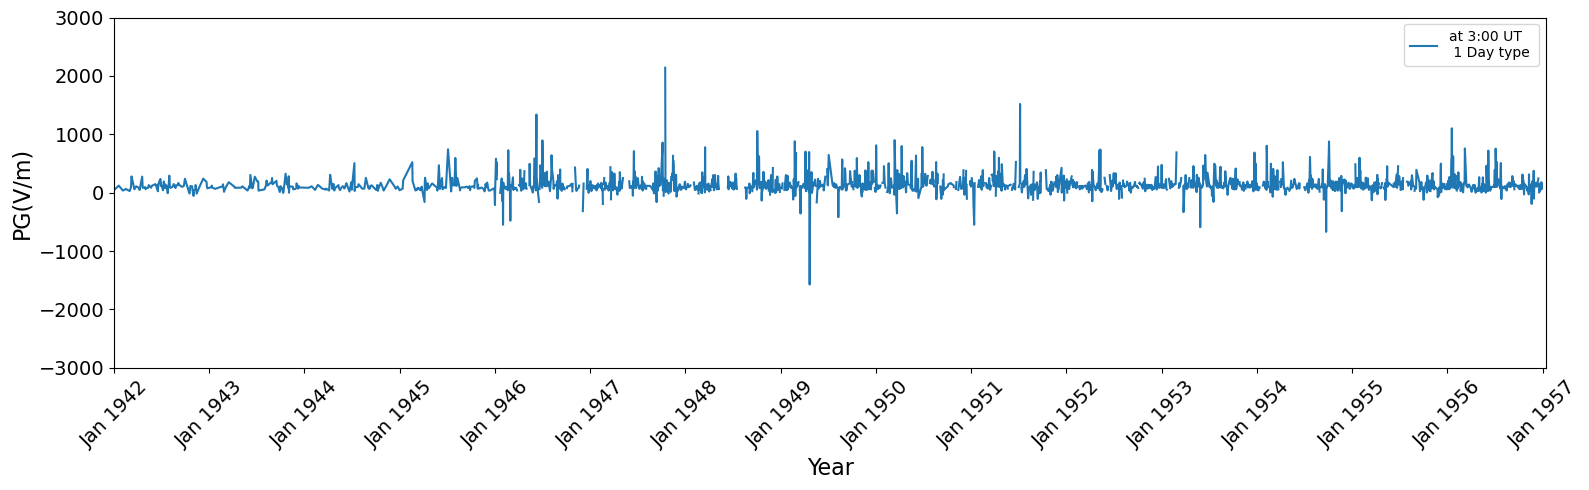

In [66]:
i=3
dt=1

daytype_df =select_df[dt]
daytype_df = daytype_df.sort_values('date')

plt.figure(figsize=(16, 5))

#plt.scatter(daytype_df['date'], daytype_df[str(i)], s=5,label=f'at {i}:00 UT \n {dt} Day type ' )
plt.plot(daytype_df['date'], daytype_df[str(i)], label=f'at {i}:00 UT \n {dt} Day type ')
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator(1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.set_xlim(pd.Timestamp('1942-01-01'),
            pd.Timestamp('1957-01-15'))
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)
plt.xlabel('Year', fontsize=16)
plt.ylabel('PG(V/m)', fontsize=16)
#plt.title('Selected hour from 1927-1956')
plt.legend()
plt.xticks(rotation=45)
plt.ylim(-3000, 3000)
plt.tight_layout()
plt.savefig(f'curve_1927_56_{i}_daytype_{dt}.png', dpi=300)
plt.show()

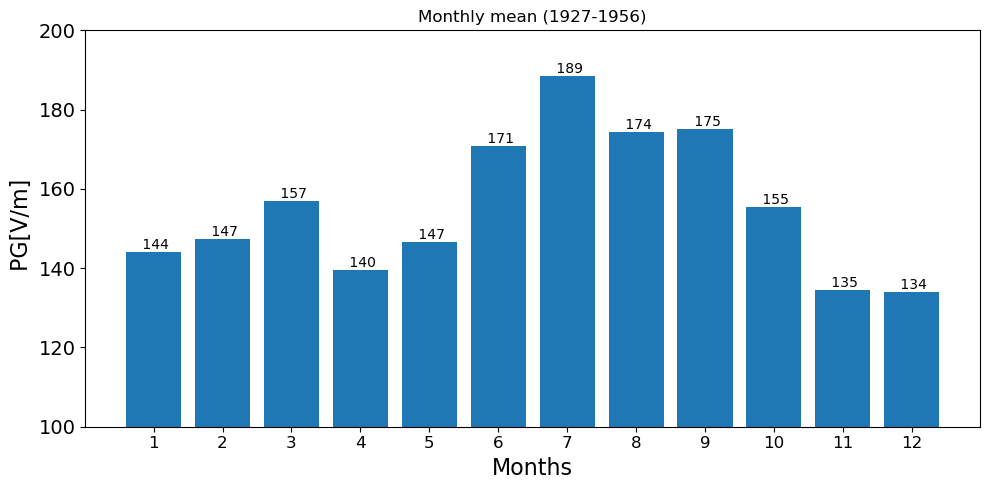

In [67]:
# MONTHLY mean

plt.figure(figsize=(10,5))
x = range(1,13)
y=monthly_mean.values
plt.bar(x, y,  width=0.8) # marker='o'
plt.ylim(100,200)
for i, v in enumerate(y):
   # if np.isfinite(v):
        plt.text(x[i], v,
                 f' {v:.0f}',   # or .1f if you want decimals
                 ha='center',
                 va='bottom',
                 
                 fontsize=10)
#plt.xticks(range(1, 25))

#plt.xticks(fontsize=14)
plt.xticks(x,  fontsize=12)
plt.yticks(fontsize=14)
plt.xlabel('Months',  fontsize=16)
plt.ylabel(' PG[V/m]',  fontsize=16)
plt.title('Monthly mean (1927-1956)')
plt.tight_layout()#rect=[0.05, 0.05, 1, 1])
plt.savefig(fig_out+ 'monthly_mean.png', dpi=300)#name_+
plt.show()

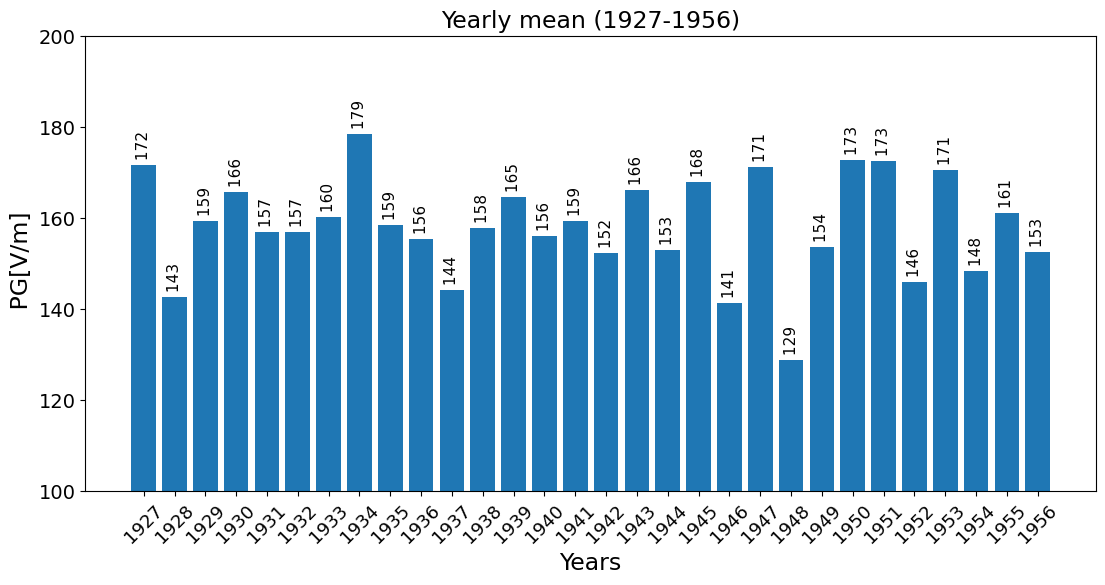

In [68]:
# Yearly mean
plt.figure(figsize=(12,7))
#x=range(1927,1957)

#years = np.arange(1927,1957)
years = yearly_stats.index
y = yearly_mean.values
x = np.arange(len(y))
plt.bar(x,y ,  width=0.8) # marker='o'
plt.ylim(100,200)
#for i, v in enumerate(y):
#    plt.text(i, v + max(y)*0.01, f'{v:.0f}', ha='center', va='bottom', rotation=90, fontsize=7)
for i, v in enumerate(y):
    if np.isfinite(v):
        plt.text(i, v,
                 f' {v:.0f}',   
                 ha='center',
                 va='bottom',
                  rotation=90,
                 fontsize=11)
#plt.xticks(range(1, 25))

plt.xticks(x, years, rotation=45, fontsize=13)
#plt.xticks(np.arange(1927, 1957, 2),fontsize=14, rotation=45)
plt.yticks(fontsize=14)
plt.xlabel('Years',  fontsize=17)
plt.ylabel(' PG[V/m]',  fontsize=17)
plt.title('Yearly mean (1927-1956)',  fontsize=17)
plt.tight_layout(rect=[0.05, 0.1, 0.98, 0.95])
plt.savefig(fig_out+ 'yearly_mean.png', dpi=300)#name_+
plt.show()

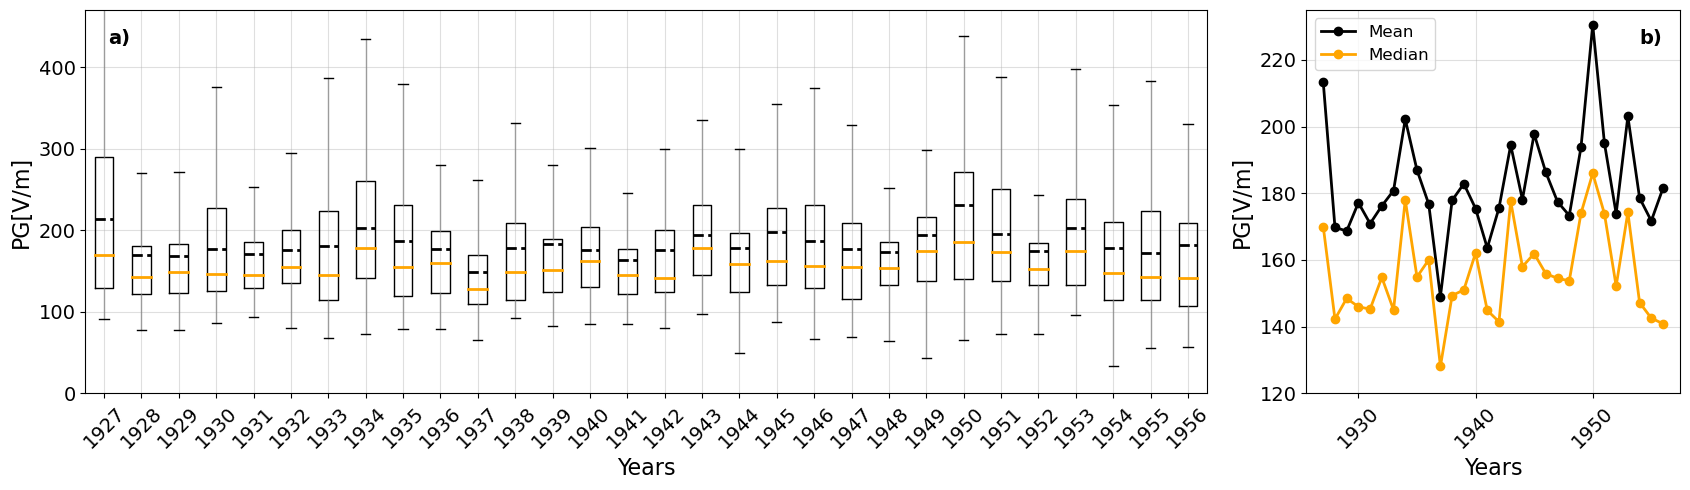

In [69]:
years = np.arange(1927, 1957)

groups_year = [
    df_0[df_0['YYYY'] == y]['daily_mean'].dropna()
    for y in years
]

means = [g.mean() for g in groups_year]
medians = [g.median() for g in groups_year]

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 5),
    gridspec_kw={'width_ratios': [3, 1]}
)

# boxplot
axes[0].boxplot(
    groups_year,
    showfliers=False,
    showmeans=True,
    meanline=True,
    whiskerprops=dict(color='gray', linewidth=1, alpha=0.7),
    medianprops=dict(color='orange', linewidth=2),
    meanprops=dict(color='black', linewidth=2)
)

axes[0].set_xticks(range(1, len(years)+1))
axes[0].set_xticklabels(years, rotation=45, fontsize=14)
axes[0].set_ylabel('PG[V/m]', fontsize=16)
axes[0].set_xlabel('Years', fontsize=16)
axes[0].set_ylim(0, 470)
axes[0].text(
        0.02, 0.95,
        'a)',
        transform=axes[0].transAxes,
        fontsize=14,
        fontweight='bold',
        va='top'
    )

# mean/median plot
axes[1].plot(years, means, marker='o', color='black', linewidth=2, label='Mean')
axes[1].plot(years, medians, marker='o', color='orange', linewidth=2, label='Median')

axes[1].set_xlabel('Years', fontsize=16)
axes[1].set_ylabel('PG[V/m]', fontsize=16)
axes[1].set_ylim(120, 235)
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(fontsize=12)
axes[1].text(
        0.89, 0.95,
        'b)',
        transform=axes[1].transAxes,
        fontsize=14,
        fontweight='bold',
        va='top'
    )

for ax in axes:
    ax.tick_params(labelsize=14)
    ax.grid(True, alpha=0.4)

plt.tight_layout()
plt.savefig(fig_out+ 'Figure13.png', dpi=300)
plt.show()

Min: 33.6
Max: 599.125
Min: 67.20833333333333
Max: 352.9166666666667
Min: 33.60
Max: 863.75
Variation: 2470.68%


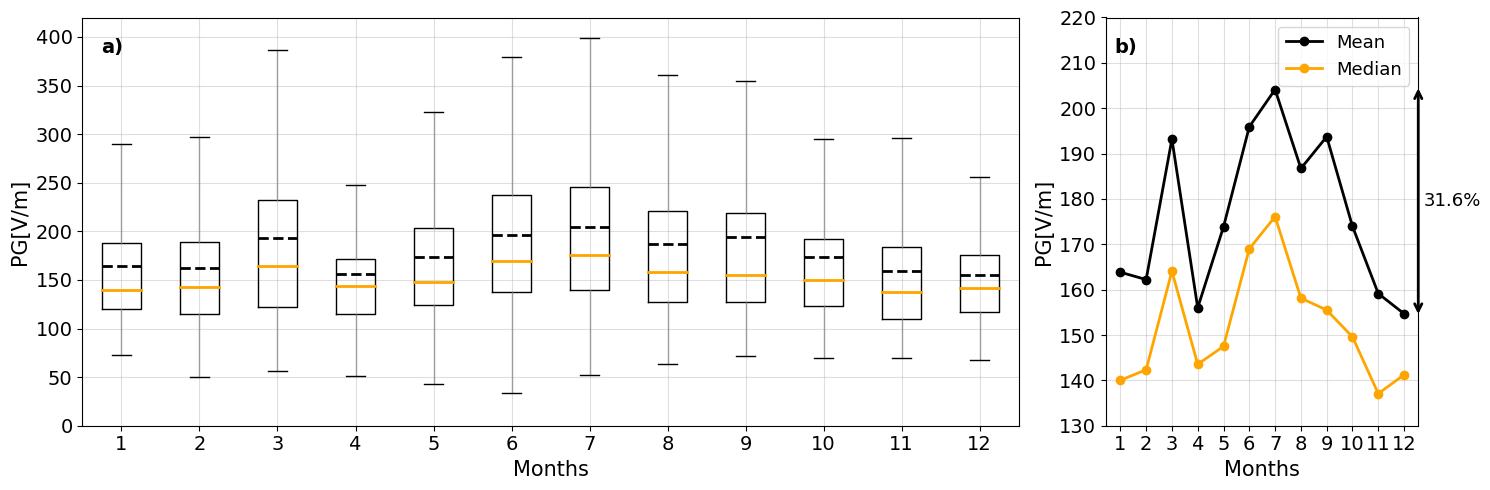

In [70]:
groups_month = [
    df_0[df_0['MM'] == m]['daily_mean'].dropna()
    for m in range(1, 13)
]


june = df_0[df_0['MM'] == 6]['daily_mean'].dropna()

print('Min:', june.min())
print('Max:', june.max())

december = df_0[df_0['MM'] == 12]['daily_mean'].dropna()

print('Min:', december.min())
print('Max:', december.max())

min_val = df_0['daily_mean'].min()
max_val = df_0['daily_mean'].max()

percentage_variation = ((max_val - min_val) / abs(min_val)) * 100

print(f'Min: {min_val:.2f}')
print(f'Max: {max_val:.2f}')
print(f'Variation: {percentage_variation:.2f}%')

monthly_variation = df_0.groupby('MM')['daily_mean'].agg(['min', 'max']).mean()

monthly_variation['variation_%'] = (
    (monthly_variation['max'] - monthly_variation['min'])
    / monthly_variation['min']#.abs()
) * 100

#print(monthly_variation)


months = range(1, 13)
means = [g.mean() for g in groups_month]
#print (months, means)
medians = [g.median() for g in groups_month]

fig, axes = plt.subplots(1, 2, figsize=(15,5), gridspec_kw={'width_ratios': [3, 1]})

# --- left: boxplot ---
axes[0].boxplot(
    groups_month,
    showfliers=False,
    showmeans=True,
    whiskerprops=dict(color='gray', linewidth=1, alpha=0.7),
    medianprops=dict(color='orange', linewidth=2),

    meanline=True,
    meanprops=dict(
        color='black',       #  marker='o',         markersize=7
        linewidth=2
    )

)

axes[0].set_xlabel('Months', fontsize=15)
axes[0].set_ylabel('PG[V/m]', fontsize=15)
axes[0].set_ylim(0, 420)
#axes[0].set_title('Monthly distribution', fontsize=15)

axes[0].text(
        0.02, 0.95,
        'a)',
        transform=axes[0].transAxes,
        fontsize=14,
        fontweight='bold',
        va='top'
    )


# --- right: mean / median only ---
axes[1].plot(range(1, 13), means, color='black', marker='o', linewidth=2, label='Mean')
axes[1].plot(range(1, 13), medians, color='orange', marker='o', linewidth=2, label='Median')

axes[1].set_xlabel('Months', fontsize=15)
axes[1].set_ylabel('PG[V/m]', fontsize=15)
axes[1].set_ylim(130, 220)
#axes[1].set_title('Mean and median', fontsize=15)
axes[1].legend(fontsize=13)
axes[1].annotate(
    '',
    xy=(12.55, 205),        # arrow head
    xytext=(12.55, 154),    # arrow tail/text position
    arrowprops=dict(
        arrowstyle='<->',
        color='black',
        linewidth=2
    ),
    ha='center',
    va='center',
    fontsize=13
)

axes[1].text(
        0.025, 0.95,
        'b)',
        transform=axes[1].transAxes,
        fontsize=14,
        fontweight='bold',
        va='top'
    )
axes[1].text(
    12.75, (204 + 155) / 2,
    '31.6%',
    fontsize=13,
    va='center'
)
for ax in axes:
    ax.set_xticks(range(1, 13))
    ax.tick_params(labelsize=14)
    ax.grid(True, alpha=0.4)

plt.tight_layout()
plt.savefig(fig_out+ 'Figure11.png', dpi=300)
plt.show()

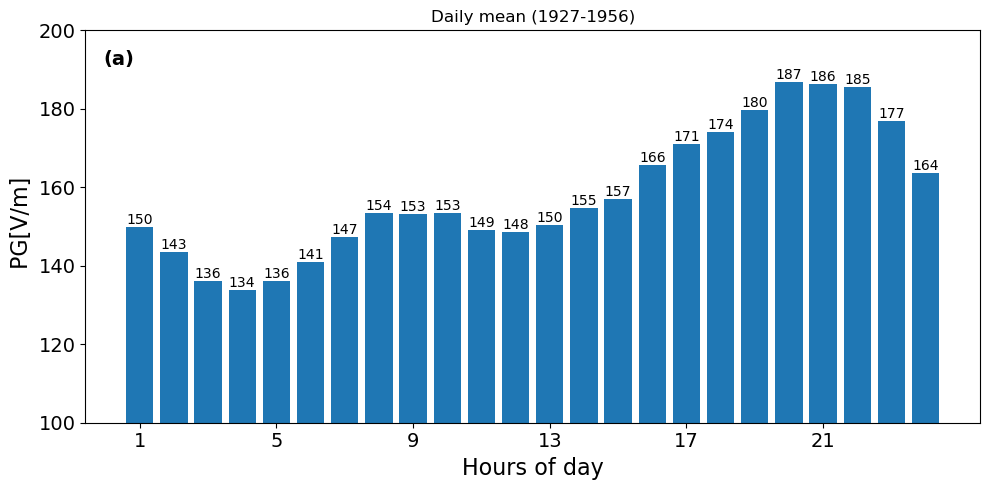

In [71]:
# Yearly mean
label = ['(a)', '(b)', '(c)']
plt.figure(figsize=(10,5))
x = range(1,25)

ax = plt.gca()
ax.text(
        0.02, 0.95,
        label[0],
        transform=ax.transAxes,
        fontsize=14,
        fontweight='bold',
        va='top'
    )

# x-axis every 1 hour
ax.xaxis.set_major_locator(MultipleLocator(4))

y=hourly_avg.values
plt.bar(x, y,  width=0.8) # marker='o'
plt.ylim(100,200)
for i, v in enumerate(y):
    if np.isfinite(v):  # ✔ only valid numbers
        plt.text(x[i], v, f'{v:.0f}',
                 ha='center', va='bottom', fontsize=10)

#plt.xticks(range(1, 25))
#plt.grid(True)
plt.xticks(np.arange(1,25, 4),fontsize=14)#, rotation=45
plt.yticks(fontsize=14)
plt.xlabel('Hours of day',  fontsize=16)
plt.ylabel(' PG[V/m]',  fontsize=16)
plt.title('Daily mean (1927-1956)')
plt.tight_layout()#rect=[0.05, 0.05, 1, 1])
plt.savefig(fig_out+ 'Figure10a.png', dpi=300)#name_+

plt.show()

In [72]:
hour_cols = [str(i) for i in range(1, 25)]
v_main = df_main[hour_cols].replace(9999, pd.NA)
v_main = v_main.apply(pd.to_numeric, errors='coerce')
v0 = df_0[hour_cols].replace(9999, pd.NA)
v0 = v0.apply(pd.to_numeric, errors='coerce')

v1 = df_1[hour_cols].replace(9999, pd.NA)
v1 = v1.apply(pd.to_numeric, errors='coerce')
v2 = df_2[hour_cols].replace(9999, pd.NA)
v2 = v2.apply(pd.to_numeric, errors='coerce')

#valid300 = valid.where((valid <= 300) & (valid >= 0))
ijk =2
v = [ v0,v1,v2,v_main]
dt= ['Day type 0','Day type 1', 'Day type 2', 'All']
curve_color=['red', 'blue', 'orange', 'black']

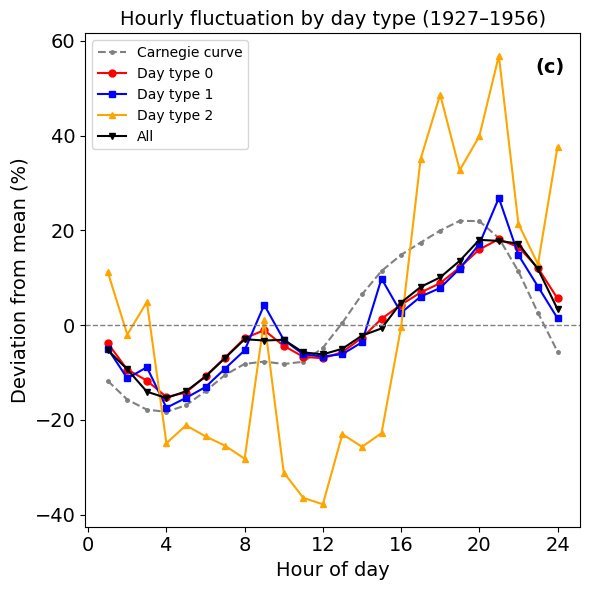

In [75]:
label = ['(a)', '(b)', '(c)']
#curve_color = ['#CC79A7', '#56B4E9', '#E69F00', '#000000']
markers = ['o', 's', '^', 'v']


   # column-wise mean
plt.figure(figsize=(6,6))

ax = plt.gca()

# x-axis every 1 hour
ax.xaxis.set_major_locator(MultipleLocator(4))
ax.text(
        0.91, 0.95,
        label[2],
        transform=ax.transAxes,
        fontsize=14,
        fontweight='bold',
        va='top'
    )
x = range(1, 25)
carnegie_mean = np.mean(carnegie)
carnegie_percent =((carnegie - carnegie_mean)*100)/carnegie_mean

plt.plot(x, carnegie_percent, linestyle='--',
             marker='.',
             markersize=5, 
             color='gray',
             label= "Carnegie curve")

plt.title(f'Hourly fluctuation by day type (1927–1956)', fontsize=14)#

for i in range(0,4):
    hourly_mean = v[i].mean(axis=0)
 
    hourly_percent = ((hourly_mean - hourly_mean.mean())* 100) / hourly_mean.mean() 

    plt.plot(x, hourly_percent.values,
             linestyle='-',
             #marker='.',
             marker=markers[i],
             markersize=5,
             color=curve_color[i], 
             label=f'{dt[i]}')


    
plt.axhline(0, color='grey', linestyle='dashed', linewidth=1)
#plt.xticks(range(1, 25))
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel('Hour of day',  fontsize=14)
plt.ylabel('Deviation from mean (%)',  fontsize=14)
plt.legend()
plt.tight_layout()#rect=[0.05, 0.05, 1, 1])
plt.savefig(fig_out+ 'Figure10c.png', dpi=300)#name_+
plt.show()

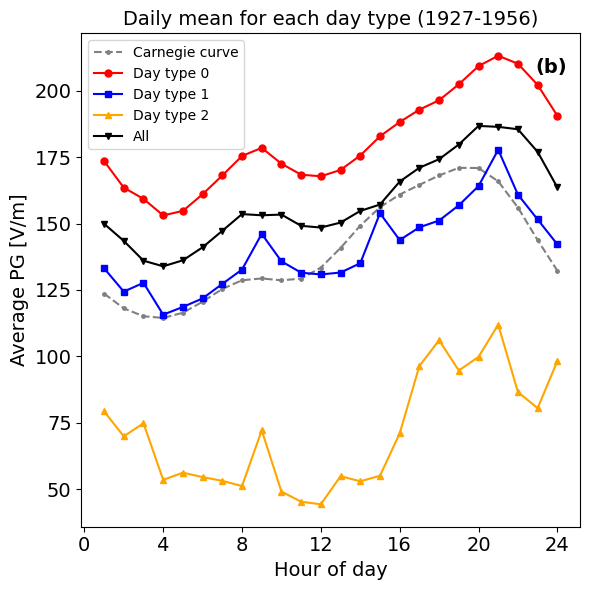

In [77]:
plt.figure(figsize=(6,6))
x = range(1, 25)

plt.title(f'Daily mean for each day type (1927-1956)', fontsize=14)

ax = plt.gca()

# x-axis every 1 hour
ax.xaxis.set_major_locator(MultipleLocator(4))
ax.text(
        0.91, 0.95,
        label[1],
        transform=ax.transAxes,
        fontsize=14,
        fontweight='bold',
        va='top'
    )
plt.plot(x, carnegie, linestyle='--',
             marker='.',
             markersize=5, 
             color='gray',
             label= "Carnegie curve")
for i in range(0,4):
    hourly_mean = v[i].mean(axis=0)

    plt.plot(x, hourly_mean.values, 
             linestyle='-',
             #marker='.',
             marker=markers[i],
             markersize=5,
             color=curve_color[i], 
             label=f'{dt[i]}')

#plt.xticks(range(1, 25))
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel('Hour of day',  fontsize=14)
plt.ylabel('Average PG [V/m]',  fontsize=14)
plt.legend()
plt.tight_layout()#rect=[0.05, 0.05, 1, 1])
plt.savefig(fig_out+ 'Figure10b.png', dpi=300)#name_+
plt.show()

In [ ]:

i=0   
hourly_mean = v[i].mean(axis=0)
mean_L = v[i]*100/hourly_mean.values
#print(mean_L)
median_C = statistics.median(carnegie)
mean_C = statistics.mean(carnegie)


relative_carnegie = [value*100/mean_C for value in carnegie]

plt.figure(figsize=(5,5))
x = range(1, 25)

plt.title(f'Lerwick’s Fair Weather Data vs. The Global Average ')


ax = plt.gca()

# x-axis every 1 hour
ax.xaxis.set_major_locator(MultipleLocator(4))



plt.plot(x, hourly_mean.values, 
             linestyle='-',
             marker='.',
             markersize=5,
             color=curve_color[i], 
             label= "Lerwick fair weather (1927-1956)")#f'{dt[i]}')
                
plt.plot(x, carnegie, linestyle='-',
             marker='.',
             markersize=5, 
             label= "Carnegie curve")
#plt.xticks(range(1, 25))
plt.xlabel('Hour of day')
plt.ylabel('Average PG [V/m]')
plt.legend()
plt.tight_layout()#rect=[0.05, 0.05, 1, 1])

plt.show()

In [ ]:
df_factor = pd.read_csv('factor.txt', sep='\s+')

df_factor = df_factor.rename(columns={'M': 'MM'})
df_factor = df_factor.reset_index(drop=True)


df_long = (
    df_factor
    .set_index('MM')     # months as index
    .stack()             # columns (years) → rows
    .rename('Factor')
)
df_long = df_long.swaplevel().sort_index()
df_long = df_long.reset_index()
print(df_long.columns)

monthly_mean =round((
    df_main[df_main['YYYY'] > 1945]
    .groupby(['YYYY', 'MM'])['Multiplier']
    .mean()
),0).astype(int)

df_monthly = monthly_mean.to_frame(name='Multiplier')
df_monthly = monthly_mean.reset_index()
df_monthly = df_monthly.set_index(['YYYY', 'MM'])


#print('---------------')
#print(df_monthly)

compare = pd.concat(
    [df_long['Factor'], df_monthly['Multiplier']],
    axis=1
).dropna()

max_val = compare['Multiplier'].max()

y = df_monthly['Multiplier']
x = df_long['Factor']

#print("Year:", idx[0])
#print("Month:", idx[1])

q1_x = np.percentile(x.dropna(), 25)
q3_x = np.percentile(x.dropna(), 75)

q1_y = np.percentile(y.dropna(), 25)
q3_y = np.percentile(y.dropna(), 75)

iqr_x = q3_x - q1_x
iqr_y = q3_y - q1_y

print('R ', q1_x, q3_x)
print('M ', q1_y, q3_y)

plt.figure(figsize=(6,6))

plt.scatter(df_long['Factor'], df_monthly['Multiplier'])
plt.gca().tick_params(labelsize=15)


z = np.polyfit(df_long['Factor'], df_monthly['Multiplier'], 1)
plt.plot(df_long['Factor'], z[0]*df_long['Factor'] + z[1], color='orange')


eq = f'y = {z[0]:.2f}x + {z[1]:.2f} \nIQR(R) = {iqr_x:.2f}\nIQR(M) = {iqr_y:.2f}'
plt.text(0.05, 0.95, eq,

         transform=plt.gca().transAxes,
         fontsize=12,
         verticalalignment='top')

plt.axvline(q1_x, color='gray', linestyle='--')
plt.axvline(q3_x, color='gray', linestyle='--')

plt.axhline(q1_y, color='gray', linestyle=':')
plt.axhline(q3_y, color='gray', linestyle=':')

plt.xlabel('Reduction Factor (R)',  fontsize=15)
plt.ylabel('Multiplier (M) [V/m]/mm',  fontsize=15)
plt.title('Reduction Factor vs Multiplier', fontsize=17)
plt.tight_layout()
plt.savefig(fig_out+ 'Figure7.png', dpi=300)
plt.show()


In [ ]:
df_long['level_0'] = pd.to_datetime(df_long['level_0'], format='%Y')

labels = ['(a)', '(b)', '(c)', '(d)']

fig, axes = plt.subplots(2, 2,  figsize=(15, 10), gridspec_kw={
        'width_ratios': [2, 1],
        'height_ratios': [1, 1]})

axes = axes.flatten() 

for ax in axes:
    ax.grid(True)


        
#ax = plt.gca()
#axes[0].yaxis.set_major_locator(ticker.MaxNLocator(10))  # ~6 ticks only
axes[0].grid(True)
axes[0].plot(df_main['date'], df_main['Multiplier'], label ='Multiplier variation (1946-1956)')
axes[0].set_ylim(0,200)
axes[0].yaxis.set_major_locator(ticker.MaxNLocator(5))
#axes[0].xaxis.set_major_locator(ticker.MaxNLocator(10))
axes[0].xaxis.set_major_locator(mdates.YearLocator())
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[0].minorticks_off()
axes[0].set_xlabel('Year',  fontsize=16)
axes[0].set_ylabel('Multiplier (M) [V/m]/mm',  fontsize=17)
#axes[0].tick_params(axis='x', labelbottom=False)
#axes[0].xaxis.set_visible(False)
axes[0].legend(fontsize=16)
axes[0].text(0.02, 0.95,labels[0], transform=axes[0].transAxes,
            ha='left',
            va='top',
            fontsize=14,
            fontweight='bold'
            )

#y.dropna()

mean = df_main['Multiplier'].mean()
median = df_main['Multiplier'].median()
std = df_main['Multiplier'].std()


axes[1].hist(df_main['Multiplier'].dropna(), bins=50,  orientation='horizontal', label ='Multiplier')
#axes[1].set_xlabel('Multiplier')
axes[1].set_xlabel('Frequency',fontsize=16)#
#axes[1].set_title('Distribution of Multiplier')

axes[1].sharey(axes[0])
axes[1].tick_params(left=False, labelleft=False)
#axes[1].tick_params(axis='x', labelbottom=False)
#axes[1].xaxis.set_visible(False)

axes[1].text(0.96, 0.95,             
            f'{labels[1]}\nμ={mean:.1f}\nmed={median:.1f}\nσ={std:.1f}',
            transform=axes[1].transAxes,
            ha='right',
            va='top',
            fontsize=14,
            fontweight='bold')

#axes[1].sharex(axes[3])
#axes[2].sharex(axes[0])

axes[2].scatter(df_long['level_0'], df_long['Factor'], label ='Reduction factor (1946-1956)')
axes[2].set_xlabel('Year',  fontsize=16)
axes[2].set_ylabel('Reduction Factor',  fontsize=16)
axes[2].legend(fontsize=16)
axes[2].text(0.02, 0.95,labels[2], transform=axes[2].transAxes,
            ha='left',
            va='top',
            fontsize=14,
            fontweight='bold'
            )


#.dropna()
mean1 = df_long['Factor'].mean()
median1 = df_long['Factor'].median()
std1 = df_long['Factor'].std()
axes[3].hist(df_long['Factor'], bins=50,  orientation='horizontal')
#axes[3].set_xlabel('Factor')
axes[3].set_xlabel('Frequency',  fontsize=16)
#axes[3].set_title('Distribution of Reduction Factor')  
axes[3].tick_params(left=False, labelleft=False)
axes[3].xaxis.set_major_locator(MaxNLocator(integer=True))
axes[3].sharey(axes[2])
axes[3].text(0.96, 0.95,
             f'{labels[3]}\nμ={mean1:.1f}\nmed={median1:.1f}\nσ={std1:.1f}',
             transform=axes[3].transAxes,
            ha='right',
            va='top',
            fontsize=14,
            fontweight='bold')


axes[0].tick_params(axis='both', labelsize=14)
axes[1].tick_params(axis='both', labelsize=14)
axes[3].tick_params(axis='both', labelsize=14)
axes[2].tick_params(axis='both', labelsize=14)
#plt.xlabel('Year',  fontsize=16)

                         
plt.tight_layout()
plt.savefig(fig_out+ 'Figure6.png', dpi=300)
plt.show()

In [ ]:
varo = df_main[df_main['Multiplier'] < 30]
print(varo['Multiplier'])
print(df_main[df_main['Multiplier'] < 30])

In [ ]:
#missing data
cols_to_use = [c for c in df_main.columns if c not in ['date', 'daily_mean','day_of_year', 'year_decimal', 'YYYY', 'MM', 'DD']]

missing_yearly = df_main[cols_to_use].isna().groupby(df_main['YYYY']).mean()
valid_yearly = (1 - missing_yearly)*100

plt.figure(figsize=(12,6))
sns.heatmap(valid_yearly, #cbar=False)
            cmap='Blues',# plasma  YlGn  Greens  coolwarm
            cbar_kws={'label': '% available data'})#,
  #          cbar=True)

plt.title('Yearly data availability')
plt.xlabel('Data')
plt.ylabel('Years')
plt.tight_layout()#rect=[0.05, 0.05, 1, 1])
plt.savefig(fig_out+ 'Figure1B_appendix.png', dpi=300)#name_+
plt.show()

In [ ]:
def plot_hourly_hist(df, title, filename): 
    hour_cols = [str(i) 
    for i in range(1, 25)]  #[3, 9, 15, 21]]
    valid = df[hour_cols].replace(9999, pd.NA) 
    valid = valid.apply(pd.to_numeric, errors='coerce') 
    fig, axes = plt.subplots(4, 6,  figsize=(18, 10), sharex=True, sharey=True)#figsize=(18, 10), sharex=True, sharey=True) 
    axes = axes.flatten() 
    for i, col in enumerate(hour_cols): 
        x = valid[col].dropna()

        mean = x.mean()
        median = x.median()
        std = x.std()

        axes[i].hist(valid[col].dropna(), bins=30) 
        axes[i].text(0.95, 0.95,
             f'μ={mean:.1f}\nmed={median:.1f}\nσ={std:.1f}',
             transform=axes[i].transAxes,
             ha='right', va='top',
             fontsize=13)
        
        axes[i].set_title(f'{int(col):02d}:00', fontsize=15) 
        axes[i].tick_params(labelsize=15) 
        axes[i].set_xlim(-1000, 1000)


    fig.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.savefig(fig_out + filename, dpi=300)
    plt.show()
    plt.close(fig)


plot_hourly_hist(df_before, 'Period 1', 'Figure2B_Period1.png')
plot_hourly_hist(df_after,  'Period 2', 'Figure2B_Period2.png')
#plot_hourly_hist(df_main,  'All', 'all_1927_56.png')


In [ ]:
hours1 =range(1,25) # [1, 2, 3, 9, 15, 21]
hour_cols1 = [str(i) for i in hours1]
valid1 = df_main[hour_cols1].replace(9999, np.nan)
valid_before = df_before[hour_cols1].replace(9999, np.nan)
valid_after = df_after[hour_cols1].replace(9999, np.nan)


counts1 = valid1.count()
mean1 = valid1.mean()
median1 = valid1.median()
std1 = valid1.std()

min1 = valid1.min()
max1 = valid1.max()

#percentage completeness
percent = valid1.count() / len(valid1) * 100

#missing %
missing1 = valid1.isna().mean() * 100
missing_before = valid_before.isna().mean() * 100
missing_after = valid_after.isna().mean() * 100

n_before = valid_before.notna().sum()
n_after  = valid_after.notna().sum()

print(n_before, ' ', n_after)

ka_before = valid_before.notna().mean() * 100
ka_after = valid_after.notna().mean() * 100

summary = pd.DataFrame({
    'mean (V/m)': round(mean1,0),
    'median (V/m)': median1.round(0).astype(int),    
    'min/max (V/m)': "'"+min1.round(0).astype(int).astype(str)+' / '+ max1.round(0).astype(int).astype(str),
    'std': round(std1,2),
    'q25 / q75(V/m)': valid.quantile(0.25).round(0).astype(int).astype(str)+' / '+valid.quantile(0.75).round(0).astype(int).astype(str),
    'iqr': (valid.quantile(0.75) - valid.quantile(0.25)).astype(int),
    'All available (N)': counts1.astype(str),#+' / '+ round(percent,0).astype(int).astype(str),
    'Period 1':ka_before.round(0).astype(int).astype(str),
    ' Period2 ':ka_after.round(0).astype(int).astype(str)    
})

#print(summary)
summary.to_csv('hourly_summary_statistics.csv', index=True)

target_cols = ['1', '14', '15']
all_hour_cols = [str(i) for i in range(1, 25)]

other_cols = [c for c in all_hour_cols if c not in target_cols]
mask = (
    df_before[target_cols].isna().any(axis=1) &
    df_before[other_cols].notna().all(axis=1)
)

print(df_before.loc[mask, ['date'] ])



In [ ]:
winter_months = [12, 1, 2]

df_winter_before = df_before[df_before['MM'].isin(winter_months)]

hour_cols = [str(i) for i in range(1, 25)]

winter_counts = df_winter_before[hour_cols].notna().sum()

#print(winter_counts)
print(winter_counts.sum())
winter_counts_year = df_winter_before.groupby('YYYY')[hour_cols].count()
#print(winter_counts_year)
winter_counts_total = df_winter_before[hour_cols].count()
#print(winter_counts_total)
print(winter_counts_total.sum())
winter_counts_year = (
    df_winter_before
    .groupby('YYYY')[hour_cols]
    .count()
    .sum(axis=1)
)

print(winter_counts_year)
summer_months = [6, 7, 8]

df_summer_before = df_before[df_before['MM'].isin(summer_months)]

summer_counts_year = (
    df_summer_before
    .groupby('YYYY')[hour_cols]
    .count()
    .sum(axis=1)
)

#for year, count in summer_counts_year.items():
 #   print(f"{year} - {count}")
print(summer_counts_year)

In [ ]:
winter_months = [12, 1, 2]

df_winter_after = df_after[df_after['MM'].isin(winter_months)]

winter_counts_total = df_winter_after[hour_cols].count()
#print(winter_counts_total)
print(winter_counts_total.sum())
winter_counts_year_after = (
    df_winter_after
    .groupby('YYYY')[hour_cols]
    .count()
    .sum(axis=1)
)

print(winter_counts_year_after)
summer_months = [6, 7, 8]

df_summer_after = df_after[df_after['MM'].isin(summer_months)]

summer_counts_year_after = (
    df_summer_after
    .groupby('YYYY')[hour_cols]
    .count()
    .sum(axis=1)
)

#for year, count in summer_counts_year.items():
 #   print(f"{year} - {count}")
print(summer_counts_year_after)

In [ ]:
fig, axes = plt.subplots(4, 6, figsize=(18, 10), sharex=True, sharey=True)
axes = axes.flatten()

for i, col in enumerate(hour_cols): 
    ax = axes[i] 
    x = valid[col].dropna() 
    ax.hist(x, bins=50)
    ax.set_xlim(-2000, 2000)
    ax.set_title(f'{int(col):02d}:00', fontsize=12) 
    ax.tick_params(axis='both', labelsize=10) 
    ax.minorticks_off() 

def plot_hourly_hist(df, title, filename): 
    hour_cols = [str(i) 
    for i in range(1, 25)] 
    valid = df[hour_cols].replace(9999, pd.NA) 
    valid = valid.apply(pd.to_numeric, errors='coerce') 
    fig, axes = plt.subplots(4, 6, figsize=(18, 10), sharex=True, sharey=True) 
    axes = axes.flatten() 
    for i, col in enumerate(hour_cols): 
        
        axes[i].hist(valid[col].dropna(), bins=30) 
        ax.set_xlim(-1000, 1000)
        axes[i].set_title(f'{int(col):02d}:00', fontsize=9) 
        axes[i].tick_params(labelsize=7) 


    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(fig_out + filename, dpi=300)
    plt.show()

plot_hourly_hist(df_before, 'Before 1945', 'before_1945.png')
plot_hourly_hist(df_after,  'After 1945', 'after_1945.png')
plot_hourly_hist(df_main,  'All', 'all_1927_56.png')


In [ ]:
#withouth stat
fig, axes = plt.subplots(4, 6, figsize=(18, 10), sharex=True, sharey=True)
axes = axes.flatten()
for i, col in enumerate(hour_cols):
    ax = axes[i]
    
    ax.plot(dates, valid[col], linewidth=0.7)
    ax.set_title(f'{int(col):02d}:00', fontsize=12)
    ax.set_ylim(-1500, 2000)
    ax.tick_params(labelsize=11)
    ax.tick_params(axis='x', labelrotation=45)
    ax.minorticks_off()

     # hide inner labels for cleanliness
    if i >= 18:
        ax.tick_params(labelbottom=True)
    else:
        ax.tick_params(labelbottom=False)

     # show y labels only on left column
    if i % 6 == 0:
        ax.tick_params(labelleft=True)
    else:
        ax.tick_params(labelleft=False)

plt.tight_layout()#rect=[0.05, 0.05, 1, 1])
plt.savefig(fig_out+ 'Figure3B_appendix.png', dpi=300)#name_+
plt.show()

In [ ]:
#monthly 
rolling_mean = counts['measurements'].rolling(12).mean()
plt.figure(figsize=(16, 5))
plt.bar(monthly_counts['date'], monthly_counts['count'], width=25)
plt.plot(counts['date'], rolling_mean,
         linestyle='--', linewidth=3, color='orange',
         label='Mean')

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
#ax.set_xlim(1927, 1956)
ax.set_xlim(pd.Timestamp('1927-01-01'),
            pd.Timestamp('1956-12-31'))

ax.tick_params(axis='x', labelsize=16)
ax.tick_params(axis='y', labelsize=16)
ax.set_xlabel('Year', fontsize=17)
ax.set_ylabel('Number of measurements', fontsize=17)
plt.axvline(
    pd.Timestamp('1946-01-01'),
    linestyle='--',
    color='grey',
    linewidth=3
)
plt.xticks(rotation=45)

plt.title('Monthly count of measurements', fontsize=19)

plt.tight_layout()#rect=[0.05, 0.05, 1, 1])
plt.savefig(fig_out+ 'Figure8.png', dpi=300)#name_+
plt.show()